# ChessGPT — v5: one move = one token, more data, and a look inside the model

## Where we are
| Version | Model | Unit | Bits/char | Legal move rate | Self-play plies |
|---|---|---|---|---|---|
| — | Frequency baseline | move | — | 11.2% | — |
| v1 | Bigram | character | 2.430 | 10.2% | 0.31 |
| v2 | MLP + embeddings | character | 1.558 | 36.9% | 6.58 |
| v3 | LSTM | character | 1.258 | 55.4% | 10.43 |
| v4 | GPT | character | 1.282 | 56.9% | 10.46 |

The v4 GPT learned by itself to look back at the earlier moves of the piece it is about to move. But it still has to **spell** every move character by character, and 512 characters cover only about 124 plies.

## The idea of v5
1. **One move = one token.** `Nf3`, `exd5`, `O-O`, `e8=Q+` are single symbols of a vocabulary of a few thousand moves. One prediction is one whole move: the model can no longer produce a malformed move, and the same context of 256 tokens covers 256 plies, i.e. practically every game from its first move.
2. **More data.** The test set stays exactly the same (January 2013), but training also uses **February and March 2013**: about 3 times more games. Each game is seen about once: the "one-pass" regime of real LLMs, where overfitting is not the problem.
3. **Strict legality.** As discovered in v4, `python-chess` accepts `Bxe4` even when nothing is captured. From now on we also report a **strict** legal rate: the move must be written exactly as `board.san(move)` would write it, with the correct `x`, `+` and `#`.
4. **Probability on legal moves.** With one token per move we can sum the probability that the model gives to **all** legal moves of a position: a smooth measure of how well it knows the rules, without sampling noise.
5. **Linear probes: does the model see the board?** Nobody ever shows the model a board: it only reads lists of moves. We train a simple **linear** classifier on its hidden states to answer "which piece is on each of the 64 squares?". If a linear map can read the board out of the activations, the model has built an **internal representation of the board** from text alone.

## What is new in v5
- Word-level tokenisation: vocabulary, unknown token, coverage.
- Batches of whole games, **bucketed by length** and sized by a **token budget**, to avoid wasting computation (and memory) on padding.
- **Weight tying**: the output layer reuses the embedding matrix.
- Strict legality and legal probability mass.
- **Linear probes**, layer by layer, with two ways of colouring the pieces ("white/black" against "mine/theirs").
- The trained model is saved for the web app of v6.

## Requirements and time
The notebook is self-contained: it downloads and parses the three months of Lichess games by itself (about 60 MB to download, a few minutes to parse the first time).
The training cell prints the time per step after 20 steps: expect roughly **40–70 minutes** on an 8 GB Apple M1. To make it faster, lower `PASSES` in Step 4. If the GPU runs out of memory, set `MICRO_TOKENS = 2048` and `ACCUM = 4` in Step 4.

**On Google Colab** (free GPU): upload this notebook, choose *Runtime → Change runtime type → T4 GPU*, and run `!pip install chess zstandard` in a cell before everything else. There you can also add more months to `EXTRA_MONTHS` and raise `PASSES`.

In [1]:
# --- CORE LIBRARIES ---

# PyTorch: tensors, automatic gradients, neural networks.
import torch

# Neural network layers (Embedding, Linear, LayerNorm).
import torch.nn as nn

# Functional operations: softmax, cross-entropy.
import torch.nn.functional as F

# Numerical computing.
import numpy as np

# Plotting.
import matplotlib.pyplot as plt

# python-chess: rules, legal moves, SAN parsing.
import chess

# SVG drawings of chess boards.
import chess.svg

# Zstandard decompression for the Lichess .zst files.
import zstandard

# Display SVG images and HTML in the notebook.
from IPython.display import SVG, HTML, display

# Counting occurrences.
from collections import Counter

# File and folder paths.
from pathlib import Path

# Text stream over the decompressed bytes.
import io

# Download files.
import urllib.request

# Square root and cosine for the attention scale and the learning-rate schedule.
import math

# Regular expressions (PGN cleaning, SAN grammar).
import re

# Measure execution time.
import time

# Python's random module.
import random

# Shared results file.
import json

# Independent copies of objects (CPU copy of the model).
import copy

In [2]:
# --- DEVICE, MEMORY CAP AND REPRODUCIBILITY ---

# Fastest device available: NVIDIA GPU, Apple Silicon GPU, or CPU.
if torch.cuda.is_available():

    # NVIDIA GPU.
    device = torch.device("cuda")

elif torch.backends.mps.is_available():

    # Apple Silicon GPU.
    device = torch.device("mps")

    # Cap PyTorch at 70% of the memory macOS recommends for the GPU: by default PyTorch may go well beyond it,
    # and on an 8 GB Mac the system then starts swapping and freezes. With the cap, a too-large batch raises a clear error instead.
    torch.mps.set_per_process_memory_fraction(0.7)

else:

    # CPU (slow for this model).
    device = torch.device("cpu")

# Seed for PyTorch.
torch.manual_seed(42)

# Seed for Python's random module.
random.seed(42)

# Seed for NumPy.
np.random.seed(42)

# Print the device.
print("Device:", device)

Device: mps


## Step 1 — Data: the same test set, three times more training games

- **January 2013** is parsed exactly as in v1 (same code, same file `games_2013-01.txt` if it already exists) and split exactly as before (seed 42): the validation games and the **1,000 test positions** are identical to v1–v4.
- **February and March 2013** are parsed with the same code and added to the **training set only**.

| Set | Source | Use |
|---|---|---|
| Training | 90% of January + all of February and March | learning the weights |
| Validation | 5% of January (5,781 games) | loss curves, linear probes |
| Test | 5% of January | the 1,000 test positions |

The frequency baseline keeps using the January training games only, so that it gives exactly the same 11.2% as before.

In [3]:
# --- DOWNLOAD AND PARSE LICHESS MONTHS (same parsing as v1) ---

# Folder for the chess data.
DATA_DIR = Path("data/lichess")

# Create it if needed.
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Minimum number of plies for a game to be kept (as in v1).
MIN_PLIES = 20

# Header line such as [WhiteElo "1639"].
HEADER_RE = re.compile(r'^\[(\w+) "(.*)"\]$')

# Comments in braces.
COMMENT_RE = re.compile(r"\{[^}]*\}")

# Move numbers: "12." or "12...".
MOVE_NUMBER_RE = re.compile(r"\d+\.(\.\.)?")

# Result token at the end of the move text.
RESULT_RE = re.compile(r"(1-0|0-1|1/2-1/2|\*)\s*$")

# Move annotations such as "!", "?", "!?".
ANNOTATION_RE = re.compile(r"[?!]+")


# Turn raw PGN move text into a clean space-separated list of SAN moves (identical to v1).
def clean_movetext(text):
    """'1. e4 e5 2. Nf3 { [%eval 0.2] } 2... Nc6 1-0' -> 'e4 e5 Nf3 Nc6'."""

    # Remove comments.
    text = COMMENT_RE.sub(" ", text)

    # Remove the result at the end.
    text = RESULT_RE.sub(" ", text)

    # Remove move numbers.
    text = MOVE_NUMBER_RE.sub(" ", text)

    # Remove move annotations.
    text = ANNOTATION_RE.sub("", text)

    # Single spaces.
    return " ".join(text.split())


# Download (once), parse (once) and load the cleaned games of one month.
def load_month(month):
    """Return the list of cleaned games of a Lichess month such as '2013-02'."""

    # Cleaned file, one game per line.
    games_path = DATA_DIR / f"games_{month}.txt"

    # Parse only if the cleaned file does not exist yet.
    if not games_path.exists():

        # Compressed file name used by Lichess.
        zst_name = f"lichess_db_standard_rated_{month}.pgn.zst"

        # Local path of the compressed file.
        zst_path = DATA_DIR / zst_name

        # Download only if needed.
        if not zst_path.exists():

            # Download URL.
            url = f"https://database.lichess.org/standard/{zst_name}"

            # Tell the user.
            print(f"Downloading {url} ...")

            # Download to disk.
            urllib.request.urlretrieve(url, zst_path)

        # Start time.
        start = time.perf_counter()

        # Cleaned games.
        games_month = []

        # Headers of the current game.
        headers = {}

        # Open the compressed file.
        with open(zst_path, "rb") as compressed:

            # Decompress on the fly.
            reader = zstandard.ZstdDecompressor().stream_reader(compressed)

            # Read line by line.
            for line in io.TextIOWrapper(reader, encoding="utf-8"):

                # Remove the newline and surrounding spaces.
                line = line.strip()

                # Empty line: nothing to do.
                if not line:

                    # Next line.
                    continue

                # Header line?
                match = HEADER_RE.match(line)

                # Store the header.
                if match:

                    # Key and value.
                    headers[match.group(1)] = match.group(2)

                    # Next line.
                    continue

                # Move text: one complete game.
                moves = clean_movetext(line).split()

                # Same filters as v1: not abandoned, at least MIN_PLIES plies.
                if headers.get("Termination") != "Abandoned" and len(moves) >= MIN_PLIES:

                    # Keep the game.
                    games_month.append(" ".join(moves))

                # Reset the headers for the next game.
                headers = {}

        # Write one game per line.
        games_path.write_text("\n".join(games_month), encoding="utf-8")

        # Report.
        print(f"{month}: parsed in {time.perf_counter() - start:.0f}s")

    # Load the cleaned games.
    return games_path.read_text(encoding="utf-8").split("\n")


# --- JANUARY: SAME GAMES AND SAME SPLIT AS v1-v4 ---

# January 2013 (the file written by v1, if present).
games = load_month("2013-01")

# Copy of the games.
shuffled = games[:]

# Same shuffle (seed 42).
random.Random(42).shuffle(shuffled)

# 5% validation, 5% test.
n_val = n_test = len(shuffled) // 20

# Validation games.
val_games = shuffled[:n_val]

# Test games.
test_games = shuffled[n_val:n_val + n_test]

# January training games (also used by the frequency baseline).
train_games_jan = shuffled[n_val + n_test:]

# --- EXTRA TRAINING MONTHS ---

# Months added to the training set only (on Colab you can add "2013-04", "2013-05", ...).
EXTRA_MONTHS = ["2013-02", "2013-03"]

# All extra games.
extra_games = [g for month in EXTRA_MONTHS for g in load_month(month)]

# Full training set.
train_games = train_games_jan + extra_games

# Summary.
print(f"Train: {len(train_games):,} games ({len(train_games_jan):,} from January + {len(extra_games):,} from {', '.join(EXTRA_MONTHS)})")

# Validation and test sizes (identical to v1-v4).
print(f"Validation: {len(val_games):,} | Test: {len(test_games):,}")

Train: 373,653 games (104,066 from January + 269,587 from 2013-02, 2013-03)
Validation: 5,781 | Test: 5,781


## Step 2 — Tokens: one move = one symbol

### The vocabulary
Every distinct SAN move that appears at least `MIN_COUNT = 5` times in the training games becomes a token. Three special tokens come first:

| Index | Token | Meaning |
|---|---|---|
| 0 | `<pad>` | padding (never a target) |
| 1 | `<unk>` | a move too rare to have its own token |
| 2 | `;` | start and end of a game, as in v1–v4 |

A game becomes a sequence of indices: `; e4 e5 Nf3 Nc6 … ;`. Rare moves (odd promotions, unusual disambiguations such as `Qh4e1`) become `<unk>`; the **coverage** below tells how rare that is.

### Why moves instead of characters?
| | Characters (v1–v4) | Moves (v5) |
|---|---|---|
| Vocabulary | 29 | a few thousand |
| Tokens per move | 2–7 (+ space) | 1 |
| Context of 256 tokens | about 60 plies | 256 plies |
| Malformed moves | possible | impossible (every token is a real move) |
| Cost | the model must learn spelling | larger embedding and output layer |

This is the same trade-off as in real LLMs, which use **sub-word tokens** (pieces of words) rather than characters or whole words.

### Batches of whole games, bucketed by length
Each training example is **one whole game** from its first move, so the position index of a token is exactly its ply number. Games have very different lengths (20 to 250+ plies); padding a 30-ply game to 200 would waste most of the computation. So a batch takes games of **similar length**: the games are sorted by length once, and each batch is a random slice of consecutive games in that order. Padding then costs almost nothing.

### A token budget instead of a fixed number of games
With a fixed number of games, a batch of long games is much bigger than a batch of short ones: 32 games of 256 moves are 8,192 positions, and the output layer alone produces $8{,}192 \times V$ logits (about 190 MB, plus as much again for the softmax and its gradient), which is too much for an 8 GB Mac. So the batch size adapts to the length of the games:

$$
n_{\text{games}} = \max\left(1, \left\lfloor \frac{\text{token budget}}{\text{game length}} \right\rfloor\right)
$$

about 60 games of 70 moves, or 16 games of 256 moves: always about the same number of positions, so always about the same memory. Since the first game of the slice is chosen uniformly in the sorted order, every **move** of the training set has about the same chance of being in a batch.

### Few tensor shapes (for Apple GPUs)
On the `mps` backend, every new tensor shape makes PyTorch compile and **keep** a new computation graph, which uses memory of its own. With hundreds of different (games × length) shapes, that memory grows until it runs out. So the length is rounded up to a multiple of 32 and the number of games is fixed by the rounded length: there are only $256 / 32 = 8$ possible shapes, compiled once each. The extra padding is small (at most 31 positions per game) and masked anyway.

The loss is masked on padding as in v3–v4 (`-100`).

### Comparable bits per character
A move model and a character model assign probabilities to the same games (the spaces between moves carry no information once the moves are known), so the total information of a game in bits is comparable. Dividing by the number of characters of the game (as in v1–v4: every character plus the final `;`) gives an **equivalent bits per character**:

$$
\text{bpc}_{\text{eq}} = \frac{\sum_{\text{games}} \sum_{\text{moves}} -\log_2 p(\text{move} \mid \text{previous moves})}{\sum_{\text{games}} (\text{number of characters} + 1)}
$$

In [4]:
# --- VOCABULARY OF MOVES ---

# A move needs at least this many occurrences in the training games to get its own token.
MIN_COUNT = 5

# Maximum context in tokens (plies), as for the position table of the model.
BLOCK = 256

# Special tokens.
SPECIALS = ["<pad>", "<unk>", ";"]

# Their indices.
PAD_ID, UNK_ID, SEP_ID = 0, 1, 2

# Number of special tokens (the first real move has this index).
N_SPECIAL = len(SPECIALS)

# Occurrences of every move in the training games.
move_counts = Counter(m for g in train_games for m in g.split())

# Frequent moves, from the most to the least common (ties in alphabetical order).
frequent_moves = sorted((m for m, c in move_counts.items() if c >= MIN_COUNT), key=lambda m: (-move_counts[m], m))

# Vocabulary: special tokens first, then the moves.
vocab = SPECIALS + frequent_moves

# Vocabulary size.
V = len(vocab)

# Move -> index.
stoi = {m: i for i, m in enumerate(vocab)}

# Index -> move.
itos = {i: m for i, m in enumerate(vocab)}

# Share of training move occurrences that have their own token.
coverage = sum(c for m, c in move_counts.items() if m in stoi) / sum(move_counts.values())

# Report.
print(f"Distinct moves in training: {len(move_counts):,} | vocabulary: {V:,} tokens | coverage: {coverage:.4%}")

# The most common moves.
print("Most common moves:", " ".join(frequent_moves[:20]))


# Encode a game as [;, move, move, ..., ;], cut to at most BLOCK + 1 tokens.
def encode_game(game):
    """Space-separated SAN moves -> int16 array of token indices."""

    # Start token, moves (unknown ones become <unk>), end token.
    ids = [SEP_ID] + [stoi.get(m, UNK_ID) for m in game.split()] + [SEP_ID]

    # At most BLOCK inputs + 1 target.
    return np.array(ids[:BLOCK + 1], dtype=np.int16)


# --- TRAINING SET AS ONE FLAT ARRAY ---

# Start time.
start = time.perf_counter()

# One small array per game.
encoded_train = [encode_game(g) for g in train_games]

# Length (in tokens) of every training sequence.
train_lengths = np.array([len(e) for e in encoded_train])

# Start of every game in the flat array (cumulative sum of the lengths, starting at 0).
train_offsets = np.concatenate([[0], np.cumsum(train_lengths)])

# All tokens one after the other (int16 keeps it small).
train_tokens = np.concatenate(encoded_train)

# Free the list of small arrays.
del encoded_train

# Games sorted from the shortest to the longest (used to build batches of similar length).
length_order = np.argsort(train_lengths, kind="stable")

# Report.
print(f"Training tokens: {len(train_tokens):,} (encoded in {time.perf_counter() - start:.0f}s) | "
      f"games cut at {BLOCK} plies: {(train_lengths == BLOCK + 1).mean():.2%}")


# Lengths are rounded up to a multiple of this, so that tensors come in only a few shapes.
SHAPE_STEP = 32


# Round a number of positions up to the next multiple of SHAPE_STEP.
def round_up(n):
    """e.g. 70 -> 96, 96 -> 96 (with SHAPE_STEP = 32)."""

    # Ceiling division, times the step.
    return -(-n // SHAPE_STEP) * SHAPE_STEP


# A batch of whole games of similar length, with a fixed shape that depends only on the (rounded) length.
def get_batch(token_budget):
    """Return inputs (B, T) and targets (B, T) on the device, B * T <= token_budget; padding targets are -100."""

    # Random first game in the length order.
    first = np.random.randint(0, len(length_order))

    # Input length of that game (one token less than the sequence), rounded up.
    T = round_up(train_lengths[length_order[first]] - 1)

    # Batch size fixed by the rounded length: the shape (B, T) is one of a few possible shapes.
    B = max(1, token_budget // T)

    # Keep the slice inside the array (near the end, move it back).
    first = min(first, len(length_order) - B)

    # Indices of the games: consecutive in the length order, so of similar length.
    rows = length_order[first:first + B]

    # In the sparse tail of very long games, the slice may contain longer games: then use their rounded length.
    T_max = round_up(train_lengths[rows].max() - 1)

    # Longer than planned: fewer games, so that B * T stays within the budget.
    if T_max > T:

        # New length.
        T = T_max

        # New batch size.
        B = max(1, token_budget // T)

        # Keep the first B games (sorted: their maximum length can only decrease).
        rows = rows[:B]

    # Matrix filled with padding: T inputs + 1 extra column for the last target.
    batch = np.full((B, T + 1), PAD_ID, dtype=np.int64)

    # Copy every game to the left of its row.
    for r, i in enumerate(rows):

        # Tokens of game i.
        seq = train_tokens[train_offsets[i]:train_offsets[i + 1]]

        # Valid tokens first, padding after.
        batch[r, :len(seq)] = seq

    # As a tensor.
    batch = torch.from_numpy(batch)

    # Inputs: all columns but the last.
    x = batch[:, :-1]

    # Targets: all columns but the first, with padding replaced by -100.
    y = batch[:, 1:].masked_fill(batch[:, 1:] == PAD_ID, -100)

    # Both on the device.
    return x.to(device), y.to(device)


# Example batch with a small budget of 300 positions.
x_ex, y_ex = get_batch(300)

# Its shape: games x positions.
print("Example batch:", tuple(x_ex.shape))

# The first 12 inputs of the first game, as moves.
print("input :", " ".join(itos[i] for i in x_ex[0, :12].tolist()))

# The corresponding targets.
print("target:", " ".join(itos[i] for i in y_ex[0, :12].tolist()))

# --- VALIDATION SET ---

# One array per validation game.
encoded_val = [encode_game(g) for g in val_games]

# Characters of every validation game, counted as in v1-v4 (all characters + the final ';').
val_chars = np.array([len(g) + 1 for g in val_games])

# Share of validation moves that are <unk>.
val_unk = np.mean([t == UNK_ID for e in encoded_val for t in e[1:-1]])

# Report.
print(f"Validation: {len(encoded_val):,} games | unknown moves: {val_unk:.3%} | "
      f"games cut at {BLOCK} plies: {np.mean([len(e) == BLOCK + 1 for e in encoded_val]):.2%}")

Distinct moves in training: 9,668 | vocabulary: 5,721 tokens | coverage: 99.9729%
Most common moves: O-O Nf3 e4 d4 Nf6 e5 d5 Nc6 Nc3 c5 c4 e6 d6 f4 b5 h3 h6 b4 a6 c3
Training tokens: 27,071,622 (encoded in 3s) | games cut at 256 plies: 0.01%
Example batch: (4, 64)
input : ; e4 e5 Nf3 d6 Nc3 c5 Bc4 Nc6 d3 Nf6 Ng5
target: e4 e5 Nf3 d6 Nc3 c5 Bc4 Nc6 d3 Nf6 Ng5 Nd4
Validation: 5,781 games | unknown moves: 0.037% | games cut at 256 plies: 0.00%


## Step 3 — The model: the v4 GPT, bigger, with weight tying

The architecture is exactly the one of v4 (embeddings, causal multi-head attention, pre-norm blocks with residual connections and MLP, KV cache, attention maps), with three changes:

| | v4 | v5 |
|---|---|---|
| Vocabulary | 29 characters | $V$ moves (a few thousand) |
| Context | 512 characters | 256 moves |
| Width $d$ / heads / layers | 192 / 6 / 6 | 256 / 8 / 6 |

### Weight tying
With thousands of tokens, the embedding matrix $E \in \mathbb{R}^{V \times d}$ and the output matrix $W_{\text{out}} \in \mathbb{R}^{V \times d}$ are now the largest parts of the model. GPT-2 uses **the same matrix for both**:

$$
x_t = E[c_t] + P[t], \qquad z = E\, h_{\text{final}} + b
$$

The logit of a move is the dot product between the final hidden state and that move's embedding: "how similar is what the model wants to say to this move?". It halves those parameters, and every update of the output layer also improves the embeddings of rare moves.

### Hidden states for the probes
A new method `hidden(idx, n_blocks)` returns the residual stream after the first `n_blocks` blocks ($0$ = just the embeddings). Step 8 uses it to read what the model "knows" at every depth.

### Parameters
$$
|\theta| = \underbrace{V \cdot 256}_{\text{tied embedding}} + \underbrace{256 \cdot 256}_{\text{positions}} + 6 \cdot \underbrace{789{,}760}_{\text{one block}} + \underbrace{512}_{\text{final LayerNorm}} + \underbrace{V}_{\text{output bias}}
$$

where one block has $2 \cdot 2 \cdot 256$ (LayerNorms) $+ (256 \cdot 768 + 768)$ ($W_Q, W_K, W_V$) $+ (256 \cdot 256 + 256)$ ($W_O$) $+ (256 \cdot 1024 + 1024 + 1024 \cdot 256 + 256)$ (MLP) $= 789{,}760$ parameters. The cell checks the formula.

In [5]:
# --- THE MODEL ---

# Size of the vectors flowing through the network (d).
N_EMBD = 256

# Number of attention heads (each with N_EMBD / N_HEAD = 32 dimensions).
N_HEAD = 8

# Number of Transformer blocks.
N_LAYER = 6


# Multi-head causal self-attention.
class CausalSelfAttention(nn.Module):

    # Declare the weights.
    def __init__(self, n_embd, n_head):

        # Initialise the parent class.
        super().__init__()

        # The embedding size must split evenly into the heads.
        assert n_embd % n_head == 0

        # Number of heads.
        self.n_head = n_head

        # Dimensions per head (d_k).
        self.head_dim = n_embd // n_head

        # W_Q, W_K and W_V for all heads in one matrix: d -> 3d.
        self.qkv = nn.Linear(n_embd, 3 * n_embd)

        # Output projection W_O: d -> d.
        self.proj = nn.Linear(n_embd, n_embd)

    # Attention over a sequence (optionally continuing from cached keys and values).
    def forward(self, x, cache=None, return_attn=False):
        """x: (B, T, d). Returns output (B, T, d), the (keys, values) for a cache, and the attention map if asked."""

        # Batch size, new positions, embedding size.
        B, T, C = x.shape

        # Queries, keys and values of the new positions, each (B, T, d).
        q, k, v = self.qkv(x).split(C, dim=2)

        # Split d into heads and put the heads first: (B, T, d) -> (B, T, H, d_k) -> (B, H, T, d_k).
        q = q.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Same for the keys.
        k = k.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # Same for the values.
        v = v.view(B, T, self.n_head, self.head_dim).transpose(1, 2)

        # With a cache: prepend the keys and values of the positions already processed.
        if cache is not None:

            # Old keys + new keys along the time axis.
            k = torch.cat([cache[0], k], dim=2)

            # Old values + new values.
            v = torch.cat([cache[1], v], dim=2)

        # Total number of positions that can be looked at (old + new).
        T_k = k.shape[2]

        # Scores q . k / sqrt(d_k) for every pair (new position, any position): (B, H, T, T_k).
        # Dividing q (small) instead of the score matrix (large) gives the same result and saves one big T x T tensor.
        att = (q / math.sqrt(self.head_dim)) @ k.transpose(-2, -1)

        # Absolute position of every query: the new positions are the last T of the T_k.
        query_pos = torch.arange(T, device=x.device)[:, None] + (T_k - T)

        # Absolute position of every key.
        key_pos = torch.arange(T_k, device=x.device)[None, :]

        # Causal mask: a query may look at keys at its own position or before (True = allowed).
        allowed = key_pos <= query_pos

        # Forbidden scores become -infinity, i.e. weight 0 after the softmax ("_": in place, again to save memory).
        att.masked_fill_(~allowed, float("-inf"))

        # Attention weights alpha: each row sums to 1.
        att = F.softmax(att, dim=-1)

        # Weighted average of the values: (B, H, T, T_k) @ (B, H, T_k, d_k) -> (B, H, T, d_k).
        y = att @ v

        # Put the heads back side by side: (B, H, T, d_k) -> (B, T, H, d_k) -> (B, T, d).
        y = y.transpose(1, 2).contiguous().view(B, T, C)

        # Output projection, keys and values (for the cache), attention map (only if asked).
        return self.proj(y), (k, v), (att if return_attn else None)


# One Transformer block: communication (attention) + computation (MLP), each with a residual connection.
class Block(nn.Module):

    # Declare the sub-layers.
    def __init__(self, n_embd, n_head):

        # Initialise the parent class.
        super().__init__()

        # LayerNorm before attention.
        self.ln1 = nn.LayerNorm(n_embd)

        # Multi-head causal self-attention.
        self.attn = CausalSelfAttention(n_embd, n_head)

        # LayerNorm before the MLP.
        self.ln2 = nn.LayerNorm(n_embd)

        # MLP: d -> 4d -> GELU -> d.
        self.mlp = nn.Sequential(nn.Linear(n_embd, 4 * n_embd), nn.GELU(), nn.Linear(4 * n_embd, n_embd))

    # Forward pass of the block.
    def forward(self, x, cache=None, return_attn=False):

        # Attention on the normalised input.
        a, kv, att = self.attn(self.ln1(x), cache, return_attn)

        # Residual connection around attention.
        x = x + a

        # Residual connection around the MLP.
        x = x + self.mlp(self.ln2(x))

        # New representation, keys/values, attention map.
        return x, kv, att


# The full move-level GPT.
class GPT(nn.Module):

    # Declare the layers.
    def __init__(self, vocab_size, block_size, n_embd, n_head, n_layer):

        # Initialise the parent class.
        super().__init__()

        # Maximum context length.
        self.block_size = block_size

        # Token embedding E: one vector per move.
        self.tok_emb = nn.Embedding(vocab_size, n_embd)

        # Position embedding P: one vector per position 0..block_size-1.
        self.pos_emb = nn.Embedding(block_size, n_embd)

        # The stack of Transformer blocks.
        self.blocks = nn.ModuleList([Block(n_embd, n_head) for _ in range(n_layer)])

        # Final LayerNorm.
        self.ln_f = nn.LayerNorm(n_embd)

        # Output layer: one logit per possible next move.
        self.head = nn.Linear(n_embd, vocab_size)

        # GPT-2 initialisation of every Linear and Embedding layer.
        self.apply(self._init_weights)

        # Weight tying: the output layer uses the embedding matrix itself (same tensor, kept in sync automatically).
        self.head.weight = self.tok_emb.weight

        # Smaller initialisation for the projections that add into the residual path.
        for name, p in self.named_parameters():

            # W_O of attention and the second linear layer of the MLP.
            if name.endswith("attn.proj.weight") or name.endswith("mlp.2.weight"):

                # Standard deviation 0.02 / sqrt(2L).
                nn.init.normal_(p, mean=0.0, std=0.02 / math.sqrt(2 * n_layer))

    # Initialisation rule for one module.
    def _init_weights(self, module):

        # Linear layers.
        if isinstance(module, nn.Linear):

            # Weights from N(0, 0.02^2).
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

            # Biases at zero.
            if module.bias is not None:

                # Zero.
                nn.init.zeros_(module.bias)

        # Embedding tables.
        elif isinstance(module, nn.Embedding):

            # Vectors from N(0, 0.02^2).
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    # Residual stream after the first n_blocks blocks (0 = embeddings only), used by the linear probes.
    def hidden(self, idx, n_blocks):
        """idx: (B, T) token indices. Returns the hidden states (B, T, d)."""

        # Absolute positions 0..T-1.
        pos = torch.arange(idx.shape[1], device=idx.device)

        # Token embedding + position embedding.
        x = self.tok_emb(idx) + self.pos_emb(pos)

        # Only the first n_blocks blocks.
        for block in self.blocks[:n_blocks]:

            # Block output (keys, values and attention maps are not needed).
            x, _, _ = block(x)

        # The residual stream at that depth.
        return x

    # Forward pass.
    def forward(self, idx, cache=None, use_cache=False, return_attn=False):
        """idx: (B, T) token indices. Returns logits (B, T, V), the new cache (if use_cache), the attention maps (if return_attn)."""

        # Batch size and number of new positions.
        B, T = idx.shape

        # Positions already in the cache (0 without a cache).
        offset = 0 if cache is None else cache[0][0].shape[2]

        # The context must fit in the position table.
        assert offset + T <= self.block_size, "sequence longer than the context of the model"

        # Absolute positions of the new characters.
        pos = torch.arange(offset, offset + T, device=idx.device)

        # Token embedding + position embedding: (B, T, d) + (T, d) broadcast over the batch.
        x = self.tok_emb(idx) + self.pos_emb(pos)

        # Keys and values of every block (for the cache).
        new_cache = []

        # Attention map of every block.
        attn_maps = []

        # Through the blocks.
        for i, block in enumerate(self.blocks):

            # Block i, with its part of the cache if there is one.
            x, kv, att = block(x, None if cache is None else cache[i], return_attn)

            # Keep its keys and values.
            new_cache.append(kv)

            # Keep its attention map (None if not asked).
            attn_maps.append(att)

        # Final LayerNorm and output layer.
        logits = self.head(self.ln_f(x))

        # Logits, cache and attention maps (None when not asked for).
        return logits, (new_cache if use_cache else None), (attn_maps if return_attn else None)


# Create the model on the device.
model = GPT(V, BLOCK, N_EMBD, N_HEAD, N_LAYER).to(device)

# Count the parameters (the tied matrix is counted once).
n_params = sum(p.numel() for p in model.parameters())

# The formula of the markdown above.
expected = V * N_EMBD + BLOCK * N_EMBD + N_LAYER * 789_760 + 2 * N_EMBD + V

# Report.
print(f"Parameters: {n_params:,} (formula: {expected:,}) | vocabulary {V:,} x {N_EMBD} = {V * N_EMBD:,} in the tied embedding")

# Same tensor for input and output: weight tying is active.
assert model.head.weight is model.tok_emb.weight

# Quick check on the example batch.
logits_ex, _, _ = model(x_ex)

# At initialisation the prediction is almost uniform: loss close to ln(V).
print(f"Initial loss: {F.cross_entropy(logits_ex.reshape(-1, V), y_ex.reshape(-1), ignore_index=-100).item():.3f}  (uniform: {math.log(V):.3f})")

Parameters: 6,274,905 (formula: 6,274,905) | vocabulary 5,721 x 256 = 1,464,576 in the tied embedding
Initial loss: 8.660  (uniform: 8.652)


## Step 4 — Training: about one pass over all the games

| Setting | Value |
|---|---|
| Batch | 2 micro-batches $\times$ about 4,096 positions (whole games, token budget of Step 2) = about 8,000 moves per step |
| Steps | enough for `PASSES = 1` pass over the training games (computed below) |
| Optimizer | AdamW, $\beta = (0.9, 0.99)$, weight decay 0.1 on matrices only |
| Learning rate | warmup to $10^{-3}$ in 200 steps, cosine decay to $10^{-4}$ |
| Gradient clipping | maximum norm 1.0 |

Everything is as in v4: gradient accumulation, two parameter groups, warmup + cosine.

### One pass, no dropout
With about 350,000 games and a single pass, every game is seen about once: the model cannot memorise games it has never seen twice, so the validation loss should follow the training loss closely. This is how large language models are trained: more data instead of more epochs.

### Evaluation
- Every 250 steps: average loss **per move** on 1,024 fixed validation games, in bits. The evaluation uses the same token budget as training, so it reuses the same 8 tensor shapes and needs no extra memory.
- At the end: all validation games, also converted to **equivalent bits per character** (Step 2) to compare with v1–v4.

3,304 steps of about 8,192 positions
0.52 s/step -> about 28 minutes for 3,304 steps (plus evaluations)
step   250/3304 | train 8.110 bits/move | val 6.796 bits/move | grad norm 1.23 | 116s
step   500/3304 | train 5.963 bits/move | val 5.920 bits/move | grad norm 0.97 | 229s
step   750/3304 | train 5.368 bits/move | val 5.510 bits/move | grad norm 0.91 | 342s
step  1000/3304 | train 5.084 bits/move | val 5.201 bits/move | grad norm 0.86 | 455s
step  1250/3304 | train 4.789 bits/move | val 5.023 bits/move | grad norm 0.89 | 590s
step  1500/3304 | train 4.569 bits/move | val 4.821 bits/move | grad norm 0.85 | 712s
step  1750/3304 | train 4.484 bits/move | val 4.679 bits/move | grad norm 0.87 | 827s
step  2000/3304 | train 4.331 bits/move | val 4.539 bits/move | grad norm 0.88 | 945s
step  2250/3304 | train 4.257 bits/move | val 4.438 bits/move | grad norm 0.88 | 1061s
step  2500/3304 | train 4.120 bits/move | val 4.359 bits/move | grad norm 0.88 | 1178s
step  2750/3304 | train 4.090 bits

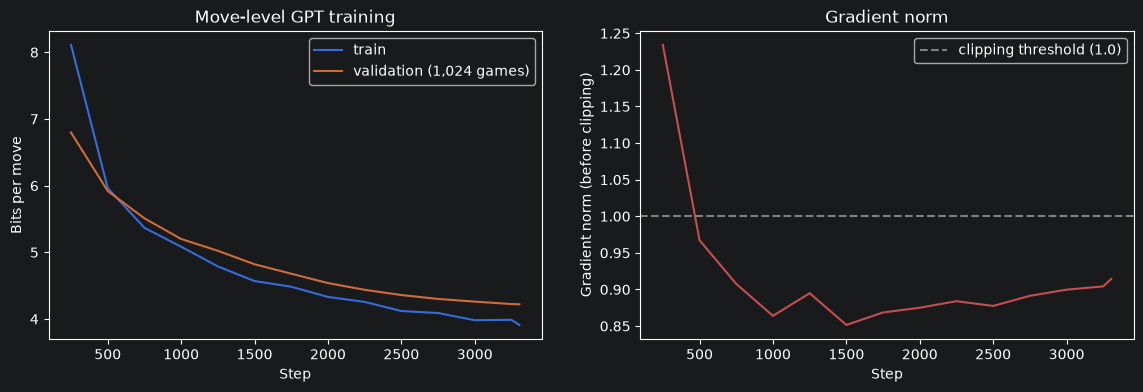

In [6]:
# --- TRAINING SETTINGS ---

# Passes over the training games.
PASSES = 1

# Positions per micro-batch (token budget: on the GPU at once). Set 2048 (and ACCUM = 4) if memory runs out.
MICRO_TOKENS = 4096

# Micro-batches per step (effective batch: about 8,192 positions).
ACCUM = 2

# Optimisation steps for PASSES passes over all training tokens.
STEPS = int(PASSES * len(train_tokens) / (MICRO_TOKENS * ACCUM))

# Peak learning rate.
LR_MAX = 1e-3

# Final learning rate.
LR_MIN = 1e-4

# Warmup steps.
WARMUP = 200

# Maximum gradient norm.
CLIP = 1.0

# Evaluate every EVAL_EVERY steps.
EVAL_EVERY = 250

# Report.
print(f"{STEPS:,} steps of about {MICRO_TOKENS * ACCUM:,} positions")

# --- OPTIMISER WITH TWO PARAMETER GROUPS ---

# Matrices and embedding tables: with weight decay.
decay_params = [p for p in model.parameters() if p.dim() >= 2]

# Biases and LayerNorm parameters: without weight decay.
no_decay_params = [p for p in model.parameters() if p.dim() < 2]

# AdamW with the two groups.
optimizer = torch.optim.AdamW([{"params": decay_params, "weight_decay": 0.1},
                               {"params": no_decay_params, "weight_decay": 0.0}], lr=LR_MAX, betas=(0.9, 0.99))


# Learning-rate multiplier for step s.
def lr_factor(s):
    """Linear warmup, then cosine decay from LR_MAX to LR_MIN."""

    # Warmup.
    if s < WARMUP:

        # Fraction of the warmup done.
        return (s + 1) / WARMUP

    # Progress of the cosine phase, from 0 to 1.
    progress = (s - WARMUP) / max(1, STEPS - WARMUP)

    # Cosine between 1 and LR_MIN / LR_MAX.
    return LR_MIN / LR_MAX + 0.5 * (1 - LR_MIN / LR_MAX) * (1 + math.cos(math.pi * progress))


# Scheduler.
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_factor)


# Total loss on a list of encoded validation games.
@torch.no_grad()
def eval_games(encoded, token_budget=MICRO_TOKENS):
    """Return (sum of the NLL in nats over all targets, number of targets)."""

    # Evaluation mode.
    model.eval()

    # On Apple GPUs, give back the memory cached by the training steps before evaluating.
    if device.type == "mps":

        # Release unused cached blocks.
        torch.mps.empty_cache()

    # Process the games from the shortest to the longest (little padding).
    order = np.argsort([len(e) for e in encoded])

    # Running sums on the GPU.
    total_nll = torch.zeros((), device=device)

    # Number of targets.
    total_targets = 0

    # Position in the sorted order.
    i = 0

    # Groups of games with the same few shapes as in training.
    while i < len(order):

        # Rounded input length of the shortest remaining game.
        T = round_up(len(encoded[order[i]]) - 1)

        # Batch size fixed by the rounded length (same rule as get_batch).
        B = max(1, token_budget // T)

        # Number of games of this group: at most B, all with input length <= T.
        n = 0

        # Add games while they fit.
        while n < B and i + n < len(order) and len(encoded[order[i + n]]) - 1 <= T:

            # One more game.
            n += 1

        # The games of this group.
        group = [encoded[j] for j in order[i:i + n]]

        # Next group starts after this one.
        i += n

        # Padded matrix with the fixed shape (B, T + 1); missing rows stay padding (all their targets are ignored).
        mat = np.full((B, T + 1), PAD_ID, dtype=np.int64)

        # Copy every game.
        for r, e in enumerate(group):

            # Valid tokens first.
            mat[r, :len(e)] = e

        # As a tensor.
        mat = torch.from_numpy(mat)

        # Inputs on the device.
        x = mat[:, :-1].to(device)

        # Targets with padding masked, on the device.
        y = mat[:, 1:].masked_fill(mat[:, 1:] == PAD_ID, -100).to(device)

        # Logits of every position.
        logits, _, _ = model(x)

        # Sum of the NLL over the real targets.
        total_nll += F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), ignore_index=-100, reduction="sum")

        # Count the real targets.
        total_targets += int((y != -100).sum())

    # Back to training mode.
    model.train()

    # Give the cached GPU memory back (only on Apple GPUs).
    if device.type == "mps":

        # Release unused cached blocks.
        torch.mps.empty_cache()

    # Sum and count.
    return total_nll.item(), total_targets


# 1,024 fixed validation games for the periodic evaluation.
val_sample = encoded_val[:1024]

# History for the plots.
history = {"step": [], "train": [], "val": [], "grad_norm": []}

# Running sums kept on the GPU.
running_loss = torch.zeros((), device=device)

# Running sum of gradient norms.
running_norm = torch.zeros((), device=device)

# Start time.
start = time.perf_counter()

# Training mode.
model.train()

# Training loop.
for step in range(1, STEPS + 1):

    # Reset gradients once per step.
    optimizer.zero_grad(set_to_none=True)

    # Gradient accumulation over ACCUM micro-batches.
    for _ in range(ACCUM):

        # A micro-batch of whole games of similar length, about MICRO_TOKENS positions.
        x, y = get_batch(MICRO_TOKENS)

        # Logits of every position.
        logits, _, _ = model(x)

        # Mean cross-entropy over the real moves, divided by ACCUM.
        loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1), ignore_index=-100) / ACCUM

        # Backpropagation: gradients are added to .grad.
        loss.backward()

        # Accumulate the loss.
        running_loss += loss.detach()

    # Clip the gradient norm.
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP)

    # Update the weights.
    optimizer.step()

    # Update the learning rate.
    scheduler.step()

    # Accumulate the gradient norm.
    running_norm += norm.detach()

    # Early time check after 20 steps.
    if step == 20:

        # Wait for the GPU before reading the clock.
        loss.item()

        # Seconds per step.
        per_step = (time.perf_counter() - start) / step

        # Projected total.
        print(f"{per_step:.2f} s/step -> about {per_step * STEPS / 60:.0f} minutes for {STEPS:,} steps (plus evaluations)")

    # Periodic evaluation.
    if step % EVAL_EVERY == 0 or step == STEPS:

        # Number of steps since the last evaluation.
        n_since = step - (history["step"][-1] if history["step"] else 0)

        # Average training loss per move since the last evaluation.
        train_loss = running_loss.item() / n_since

        # Average gradient norm.
        grad_norm = running_norm.item() / n_since

        # Reset the running sums.
        running_loss.zero_()

        # Same for the norm.
        running_norm.zero_()

        # Validation loss per move.
        nll_sum, n_targets = eval_games(val_sample)

        # Average.
        val_loss = nll_sum / n_targets

        # Store.
        history["step"].append(step)

        # Training loss.
        history["train"].append(train_loss)

        # Validation loss.
        history["val"].append(val_loss)

        # Gradient norm.
        history["grad_norm"].append(grad_norm)

        # Progress line in bits per move.
        print(f"step {step:5d}/{STEPS} | train {train_loss / np.log(2):.3f} bits/move | val {val_loss / np.log(2):.3f} bits/move | "
              f"grad norm {grad_norm:.2f} | {time.perf_counter() - start:.0f}s")

# --- EXACT VALIDATION LOSS ON ALL GAMES ---

# Sum of the NLL and number of targets over all validation games.
nll_sum, n_targets = eval_games(encoded_val)

# Bits per move.
bits_per_move = nll_sum / n_targets / np.log(2)

# Equivalent bits per character: same total information, divided by the characters of the games.
bpc_eq = nll_sum / np.log(2) / val_chars.sum()

# Report.
print(f"\nValidation: {bits_per_move:.3f} bits/move | perplexity {2 ** bits_per_move:.1f} moves | "
      f"equivalent {bpc_eq:.3f} bits/char   (v3 LSTM 1.258, v4 GPT 1.282)")

# --- TRAINING CURVES ---

# Two panels.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4))

# Training loss in bits per move.
ax1.plot(history["step"], np.array(history["train"]) / np.log(2), label="train")

# Validation loss.
ax1.plot(history["step"], np.array(history["val"]) / np.log(2), label="validation (1,024 games)")

# x-axis label.
ax1.set_xlabel("Step")

# y-axis label.
ax1.set_ylabel("Bits per move")

# Title.
ax1.set_title("Move-level GPT training")

# Legend.
ax1.legend()

# Gradient norm.
ax2.plot(history["step"], history["grad_norm"], color="#C44E52")

# Clipping threshold.
ax2.axhline(CLIP, linestyle="--", color="gray", label=f"clipping threshold ({CLIP})")

# x-axis label.
ax2.set_xlabel("Step")

# y-axis label.
ax2.set_ylabel("Gradient norm (before clipping)")

# Title.
ax2.set_title("Gradient norm")

# Legend.
ax2.legend()

# Render.
plt.show()

## Step 5 — The evaluation harness for a move model

### Proposing a move
The context of a test position is `; m1 m2 … mk` (unknown moves become `<unk>`). One forward pass gives a distribution over the whole vocabulary; we sample **one token**, and that is the move. If the model picks a special token (`;`, `<unk>`, `<pad>`), the answer counts as illegal. With the KV cache (as in v4), self-play costs one token per move.

### Two legality checks
$$
\text{legal}(m) = \big[\, \texttt{parse\_san}(m) \text{ succeeds} \,\big],
\qquad
\text{strict}(m) = \text{legal}(m) \;\wedge\; \texttt{board.san}(\texttt{parse\_san}(m)) = m
$$

The strict check rejects `Bxe4` when nothing is captured, `Qh5+` when it is not check, and `Qh5` when it is.

### Probability mass on legal moves
For a position with legal moves $\mathcal{L}$:

$$
p_{\text{legal}} = \sum_{m \in \mathcal{L}} p(m \mid \text{context})
$$

The legal rate is a sample of this quantity (one draw per position); $p_{\text{legal}}$ measures it directly, without sampling noise. If $p_{\text{legal}} = 0.9$, the model puts 90% of its belief on moves that are actually possible.

### Comparison
The test positions, the frequency baseline, the self-play procedure and the phase bins are identical to v1–v4. The results of v1–v4 come from the shared file (their models were not saved, so only the old, lenient legality is available for them).

In [7]:
# --- MOVE SAMPLER WITH A KV CACHE (on the CPU) ---

# Copy of the trained model on the CPU, in evaluation mode.
model_cpu = copy.deepcopy(model).to("cpu").eval()


# Next-move distribution with a KV cache (the same logic as the v4 GPTSampler).
class MoveSampler:
    """Callable object: context (list of token indices) -> probabilities of the next move."""

    # Start with an empty cache.
    def __init__(self, model):

        # The (CPU) model.
        self.model = model

        # Context already processed.
        self.context = []

        # Keys and values of every layer; None means empty.
        self.cache = None

        # Logits after the last token processed.
        self.logits = None

    # Make the object callable.
    @torch.no_grad()
    def __call__(self, context):

        # Longer than the context of the model (very rare): keep the last BLOCK tokens, without cache.
        if len(context) > BLOCK:

            # Forget the cache.
            self.context, self.cache = [], None

            # Full forward pass on the last BLOCK tokens.
            logits, _, _ = self.model(torch.tensor([context[-BLOCK:]]))

            # Probabilities after the last token.
            return F.softmax(logits[0, -1], dim=0).numpy().astype(np.float64)

        # Length of the cached context.
        n = len(self.context)

        # If the new context does not extend the cached one, start again.
        if n == 0 or len(context) < n or context[:n] != self.context:

            # Reset the cache.
            self.context, self.cache, n = [], None, 0

        # Tokens not processed yet.
        new = context[n:]

        # Process them, if any.
        if new:

            # Only the new tokens go through the network.
            logits, self.cache, _ = self.model(torch.tensor([new]), cache=self.cache, use_cache=True)

            # Logits after the last new token.
            self.logits = logits[0, -1]

            # Remember the full context.
            self.context = list(context)

        # Softmax as float64 NumPy.
        return F.softmax(self.logits, dim=0).numpy().astype(np.float64)


# The sampler used for evaluation.
move_probs = MoveSampler(model_cpu)


# Context of a game prefix: [;, m1, ..., mk].
def context_ids(moves):
    """List of SAN moves -> list of token indices."""

    # Start token and the moves (unknown ones become <unk>).
    return [SEP_ID] + [stoi.get(m, UNK_ID) for m in moves]


# Sample an index with temperature (temperature 0 = most likely token).
def sample_from(probs, temperature=1.0):
    """p^(1/T), renormalised, one draw; argmax if temperature is 0."""

    # Greedy choice.
    if temperature == 0:

        # Most likely token.
        return int(np.argmax(probs))

    # Sharpen or flatten.
    p = probs ** (1.0 / temperature)

    # Renormalise.
    p = p / p.sum()

    # Draw.
    return int(np.random.choice(len(p), p=p))


# Token index -> move string (special tokens give an empty, invalid move).
def token_to_move(token):
    """SAN string of a move token, '' for special tokens."""

    # Real moves start at index N_SPECIAL.
    return itos[token] if token >= N_SPECIAL else ""


# --- LEGALITY CHECKS ---

# Lenient check, as in v1-v4.
def is_legal(board, san):
    """True for a legal move (python-chess ignores a wrong 'x', '+' or '#')."""

    # Try to parse.
    try:

        # Null move "--" is falsy.
        return bool(board.parse_san(san))

    # Parsing error (illegal, ambiguous or malformed).
    except ValueError:

        # Illegal.
        return False


# Strict check: legal AND written exactly as python-chess writes it.
def is_legal_strict(board, san):
    """True only if the move is legal and its SAN (captures, check, mate) is exactly right."""

    # Try to parse.
    try:

        # The move object.
        move = board.parse_san(san)

    # Parsing error.
    except ValueError:

        # Illegal.
        return False

    # Legal, and identical to the canonical SAN.
    return bool(move) and board.san(move) == san


# SAN grammar (as in v1-v4).
SAN_RE = re.compile(r"^(O-O(-O)?|[KQRBN][a-h]?[1-8]?x?[a-h][1-8]|[a-h](x[a-h])?[1-8](=[QRBN])?)[+#]?$")


# Well-formed check.
def is_well_formed(san):
    """True if the string matches the SAN grammar."""

    # Regex match.
    return SAN_RE.match(san) is not None


# Probability that the model gives to all the legal moves of a position.
def legal_mass(probs, board):
    """Sum of the probabilities of the legal moves that are in the vocabulary."""

    # Canonical SAN of every legal move.
    legal_sans = [board.san(m) for m in board.legal_moves]

    # Sum of their probabilities.
    return float(sum(probs[stoi[s]] for s in legal_sans if s in stoi))


# --- THE SAME 1,000 TEST POSITIONS ---

# Same seed as v1-v4.
pos_rng = random.Random(123)

# (moves, board) pairs.
test_positions = []

# Draw 1,000 positions.
while len(test_positions) < 1000:

    # Random test game.
    moves = pos_rng.choice(test_games).split()

    # Random cut point.
    k = pos_rng.randrange(len(moves))

    # Replay the prefix.
    board = chess.Board()

    # Each move.
    for m in moves[:k]:

        # Play it.
        board.push_san(m)

    # Store.
    test_positions.append((moves[:k], board))

# Share of test contexts containing at least one unknown move.
print(f"Test contexts with an unknown move: {np.mean([UNK_ID in context_ids(m) for m, _ in test_positions]):.1%}")


# Evaluate the move model on the test positions.
def evaluate_model(temperature=1.0):
    """Return a list of (k, legal, strict, san, legal probability mass), one per test position."""

    # Details.
    results = []

    # Each position.
    for moves, board in test_positions:

        # Next-move distribution.
        probs = move_probs(context_ids(moves))

        # Sampled move.
        san = token_to_move(sample_from(probs, temperature))

        # Store everything.
        results.append((len(moves), is_legal(board, san), is_legal_strict(board, san), san, legal_mass(probs, board)))

    # Return.
    return results


# --- FREQUENCY BASELINE (January training moves, as in v1-v4) ---

# Training move counts.
train_move_counts = Counter(m for g in train_games_jan for m in g.split())

# Distinct moves.
baseline_moves = list(train_move_counts.keys())

# Weights.
baseline_weights = list(train_move_counts.values())


# Random move with training frequencies.
def frequency_baseline(moves):
    """Weighted random move, ignoring the position."""

    # Draw.
    return random.choices(baseline_moves, weights=baseline_weights, k=1)[0]


# --- SELF-PLAY ---

# Both sides played by the model.
def self_play(n_games=200, max_plies=BLOCK - 1, temperature=1.0):
    """Return (legal plies per game, strictly legal plies per game, sequences)."""

    # Results.
    legal_plies, strict_plies, sequences = [], [], []

    # Each game.
    for _ in range(n_games):

        # New board.
        board = chess.Board()

        # Moves played.
        moves = []

        # Ply of the first move that fails the strict check (None while all are strict).
        first_strict_fail = None

        # Play.
        while len(moves) < max_plies and not board.is_game_over():

            # Next move.
            san = token_to_move(sample_from(move_probs(context_ids(moves)), temperature))

            # Stop on a special token or an illegal move.
            if not is_legal(board, san):

                # Leave.
                break

            # Remember the first strict failure.
            if first_strict_fail is None and not is_legal_strict(board, san):

                # Ply index.
                first_strict_fail = len(moves)

            # Play.
            board.push_san(san)

            # Remember.
            moves.append(san)

        # Legal plies.
        legal_plies.append(len(moves))

        # Strictly legal plies before the first strict failure.
        strict_plies.append(len(moves) if first_strict_fail is None else first_strict_fail)

        # Sequence.
        sequences.append(moves)

    # Return.
    return legal_plies, strict_plies, sequences


# Phase bins.
PHASE_BINS = [(0, 10), (10, 20), (20, 40), (40, 80), (80, 10_000)]

# Labels.
PHASE_LABELS = ["0-9", "10-19", "20-39", "40-79", "80+"]


# Average of one field of the results in each phase bin.
def rate_by_phase(results, field=1):
    """field: index in the result tuples (1 = legal, 2 = strict, 4 = legal mass)."""

    # Values.
    rates = []

    # Each bin.
    for lo, hi in PHASE_BINS:

        # Values in the bin.
        in_bin = [r[field] for r in results if lo <= r[0] < hi]

        # Mean or NaN.
        rates.append(float(np.mean(in_bin)) if in_bin else np.nan)

    # Return.
    return rates


# --- RESULTS OF THE PREVIOUS VERSIONS ---

# Shared results file.
RESULTS_PATH = DATA_DIR / "chessgpt_results.json"

# Load it (or start an empty one, e.g. on Colab).
results_all = json.loads(RESULTS_PATH.read_text()) if RESULTS_PATH.exists() else {}

# Saved values of v1-v4 (None if missing).
saved = {name: results_all.get(key, {}) for name, key in
         [("v1 bigram", "v1_bigram"), ("v2 MLP", "v2_mlp"), ("v3 LSTM", "v3_lstm"), ("v4 GPT", "v4_gpt")]}

# Per-phase legal rates: v2 approximate (read off its chart), v3 and v4 saved.
SAVED_PHASE = {"v2 MLP": [0.78, 0.42, 0.26, 0.21, 0.24],
               "v3 LSTM": saved["v3 LSTM"].get("phase_legal_rates"),
               "v4 GPT": saved["v4 GPT"].get("phase_legal_rates")}

Test contexts with an unknown move: 0.4%


## Step 6 — Results

**Expected:** a move-level model cannot write a malformed move, and with 256 plies of context and three times more data it should beat the character models clearly, especially in the middle game.

Evaluation time: 4s

model                  well-formed   legal   strict  p(legal)
frequency baseline          100.0%   11.2%     9.1%         —
v1 bigram (saved)            94.1%   10.2%        —         —
v2 MLP (saved)              100.0%   36.9%        —         —
v3 LSTM (saved)             100.0%   55.4%        —         —
v4 GPT (saved)               99.8%   56.9%        —         —
v5 move GPT                  99.0%   75.1%    70.9%     70.2%

Self-play (200 games, 6s): mean 18.73 legal plies (median 18, max 43) | strict: mean 17.45   v1 bigram: 0.30 | v2 MLP: 6.58 | v3 LSTM: 10.43 | v4 GPT: 10.46
Self-play games finished by the rules (mate, stalemate, draw): 0 of 200

By phase:                     0-9   10-19   20-39   40-79     80+
  v3 LSTM legal (saved)      91.1%   75.9%   42.7%   34.6%   48.6%
  v4 GPT legal (saved)       94.7%   73.8%   46.5%   40.4%   29.2%
  v5 legal                   98.2%   93.7%   74.0%   55.0%   54.2%
  v5 strict                  98.2%   93.2%   69

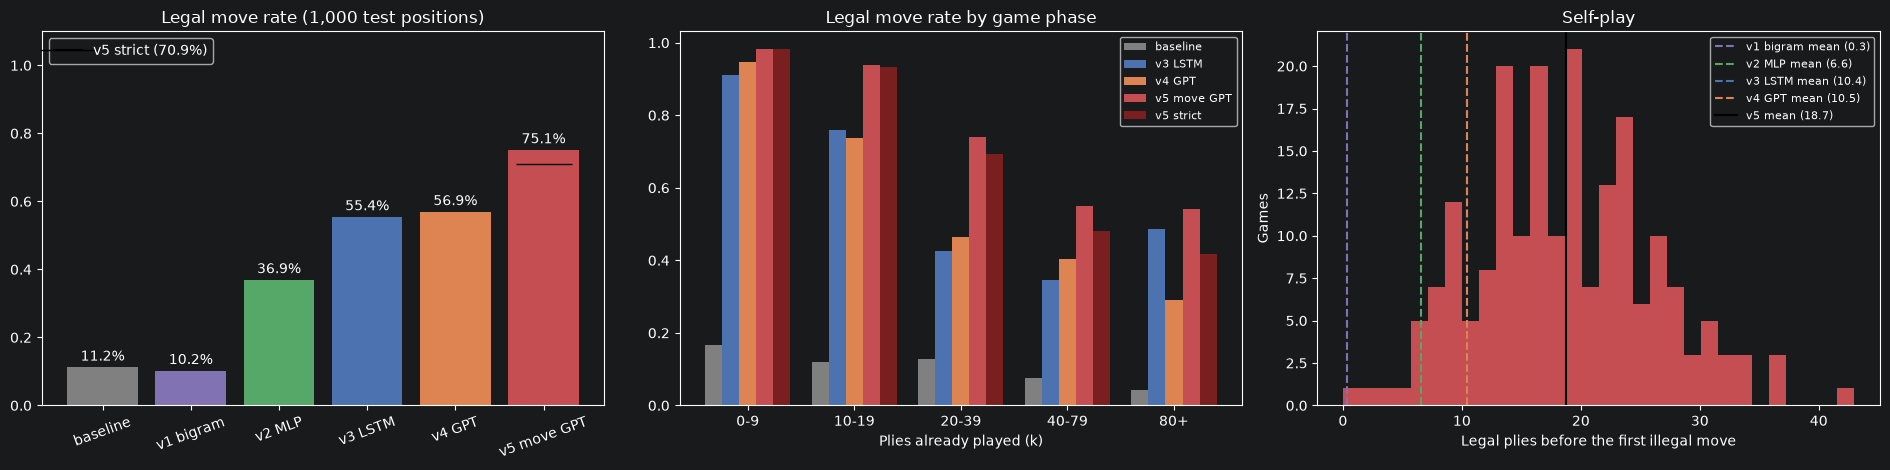

In [8]:
# --- NEXT-MOVE LEGALITY ON THE 1,000 TEST POSITIONS ---

# Fixed seeds.
np.random.seed(0)

# Same for Python's random module.
random.seed(0)

# Start time.
start = time.perf_counter()

# Baseline proposals (same random draws as in v1-v4).
base_sans = [frequency_baseline(moves) for moves, _ in test_positions]

# Baseline results in the same format as the model: (k, legal, strict, san, mass = NaN).
res_base = [(len(moves), is_legal(board, san), is_legal_strict(board, san), san, np.nan)
            for (moves, board), san in zip(test_positions, base_sans)]

# The move-level GPT.
res_v5 = evaluate_model()

# Evaluation time.
print(f"Evaluation time: {time.perf_counter() - start:.0f}s\n")

# Legal rate.
legal_v5 = np.mean([r[1] for r in res_v5])

# Strict legal rate.
strict_v5 = np.mean([r[2] for r in res_v5])

# Well-formed rate.
wf_v5 = np.mean([is_well_formed(r[3]) for r in res_v5])

# Mean probability on legal moves.
mass_v5 = np.mean([r[4] for r in res_v5])

# Baseline rates.
legal_base, strict_base = np.mean([r[1] for r in res_base]), np.mean([r[2] for r in res_base])

# Header.
print(f"{'model':<22}{'well-formed':>12}{'legal':>8}{'strict':>9}{'p(legal)':>10}")

# Baseline.
print(f"{'frequency baseline':<22}{1.0:>12.1%}{legal_base:>8.1%}{strict_base:>9.1%}{'—':>10}")

# Saved versions.
for name, r in saved.items():

    # Only if present in the file.
    if r:

        # Old, lenient legality only.
        print(f"{name + ' (saved)':<22}{r['well_formed_rate']:>12.1%}{r['legal_rate']:>8.1%}{'—':>9}{'—':>10}")

# The move-level GPT.
print(f"{'v5 move GPT':<22}{wf_v5:>12.1%}{legal_v5:>8.1%}{strict_v5:>9.1%}{mass_v5:>10.1%}")

# --- SELF-PLAY ---

# Start time.
start = time.perf_counter()

# Self-play.
v5_plies, v5_strict_plies, v5_sequences = self_play()

# Saved self-play means.
sp_saved = {name: r.get("selfplay_mean_plies") for name, r in saved.items() if r}

# Report.
print(f"\nSelf-play (200 games, {time.perf_counter() - start:.0f}s): mean {np.mean(v5_plies):.2f} legal plies "
      f"(median {np.median(v5_plies):.0f}, max {max(v5_plies)}) | strict: mean {np.mean(v5_strict_plies):.2f}   "
      + " | ".join(f"{n}: {v:.2f}" for n, v in sp_saved.items()))

# Games that reached the end of the game (mate, stalemate, draw rules) with only legal moves.
finished = [chess.Board() for _ in v5_sequences]

# Replay each game.
for b, seq in zip(finished, v5_sequences):

    # Each move.
    for m in seq:

        # Play it.
        b.push_san(m)

# How many self-play games ended by the rules of chess.
print(f"Self-play games finished by the rules (mate, stalemate, draw): {sum(b.is_game_over() for b in finished)} of {len(finished)}")

# Phase rates.
phase_legal = rate_by_phase(res_v5, 1)

# Strict.
phase_strict = rate_by_phase(res_v5, 2)

# Legal mass.
phase_mass = rate_by_phase(res_v5, 4)

# Phase table.
print("\nBy phase:                " + "".join(f"{label:>8}" for label in PHASE_LABELS))

# Saved rows.
for name in ["v3 LSTM", "v4 GPT"]:

    # Only if saved.
    if SAVED_PHASE[name]:

        # Row.
        print(f"  {name + ' legal (saved)':<24}" + "".join(f"{r:>8.1%}" for r in SAVED_PHASE[name]))

# v5 rows.
print(f"  {'v5 legal':<24}" + "".join(f"{r:>8.1%}" for r in phase_legal))

# Strict.
print(f"  {'v5 strict':<24}" + "".join(f"{r:>8.1%}" for r in phase_strict))

# Legal mass.
print(f"  {'v5 p(legal)':<24}" + "".join(f"{r:>8.1%}" for r in phase_mass))

# --- PLOTS ---

# Three panels.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(19, 4.8))

# Names and lenient legal rates of all versions that are available.
names = ["baseline"] + [n for n, r in saved.items() if r] + ["v5 move GPT"]

# Values.
values = [legal_base] + [r["legal_rate"] for r in saved.values() if r] + [legal_v5]

# Bars.
bars = ax1.bar(names, values, color=["gray", "#8172B3", "#55A868", "#4C72B0", "#DD8452", "#C44E52"][:len(names)])

# Value labels.
for bar, value in zip(bars, values):

    # Label above the bar.
    ax1.text(bar.get_x() + bar.get_width() / 2, value + 0.01, f"{value:.1%}", ha="center", va="bottom")

# Strict rate of v5 as a dark marker inside its bar.
ax1.plot([len(names) - 1], [strict_v5], marker="_", markersize=40, color="black", label=f"v5 strict ({strict_v5:.1%})")

# Room above the bars.
ax1.set_ylim(0, 1.1)

# Rotate the names.
ax1.tick_params(axis="x", rotation=20)

# Title.
ax1.set_title("Legal move rate (1,000 test positions)")

# Legend.
ax1.legend(loc="upper left")

# Phase chart.
xp = np.arange(len(PHASE_LABELS))

# Rows to draw: (label, values, colour).
phase_rows = [("baseline", rate_by_phase(res_base, 1), "gray")] + \
             [(n, SAVED_PHASE[n], c) for n, c in [("v3 LSTM", "#4C72B0"), ("v4 GPT", "#DD8452")] if SAVED_PHASE[n]] + \
             [("v5 move GPT", phase_legal, "#C44E52"), ("v5 strict", phase_strict, "#7A1F1F")]

# Width of one bar.
w = 0.8 / len(phase_rows)

# One group of bars per row.
for j, (label, vals, colour) in enumerate(phase_rows):

    # Shifted bars.
    ax2.bar(xp - 0.4 + w / 2 + j * w, vals, width=w, color=colour, label=label)

# Bin labels.
ax2.set_xticks(xp, PHASE_LABELS)

# x-axis label.
ax2.set_xlabel("Plies already played (k)")

# Title.
ax2.set_title("Legal move rate by game phase")

# Legend.
ax2.legend(fontsize=8)

# Self-play histogram.
ax3.hist(v5_plies, bins=30, color="#C44E52")

# Saved means.
for (n, v), colour in zip(sp_saved.items(), ["#8172B3", "#55A868", "#4C72B0", "#DD8452"]):

    # Vertical line.
    ax3.axvline(v, linestyle="--", color=colour, label=f"{n} mean ({v:.1f})")

# v5 mean.
ax3.axvline(np.mean(v5_plies), linestyle="-", color="black", label=f"v5 mean ({np.mean(v5_plies):.1f})")

# x-axis label.
ax3.set_xlabel("Legal plies before the first illegal move")

# y-axis label.
ax3.set_ylabel("Games")

# Title.
ax3.set_title("Self-play")

# Legend.
ax3.legend(fontsize=8)

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 7 — Temperature, examples and the longest game

- Legality at temperatures 1.0, 0.8, 0.5 and **0** (always the most likely move).
- The same 10 test positions as v3 and v4, with the probability the model puts on legal moves.
- The longest self-play game and its final position.

 temperature   legal   strict
         1.0   75.1%    70.9%
         0.8   79.4%    76.0%
         0.5   84.5%    81.9%
         0.0   87.6%    85.7%

Examples (last moves of the context -> v5 move):
  ply  34 | ...Bd4 Qe7 Qa5 b6               -> Qa4      legal                  p(legal) = 58%
  ply  49 | ...Qg6 Qxd7+ Qf7 Re7            -> Raf8     legal                  p(legal) = 35%
  ply  17 | ...d6 Nf3 d5 cxd5               -> cxd5     legal                  p(legal) = 95%
  ply   9 | ...Bc5 Nf3 d6 d4                -> Bb6      legal                  p(legal) = 95%
  ply  34 | ...Ng5 Bc5+ Bf2 Qg3+            -> Kh1      legal                  p(legal) = 53%
  ply  42 | ...gxf4 gxf4 Kf3 fxe3           -> fxe3     legal                  p(legal) = 89%
  ply   1 | ...g3                           -> d5       legal                  p(legal) = 100%
  ply   8 | ...e4 Bb4 a3 Bc5                -> Bf4      illegal                p(legal) = 97%
  ply  42 | ...Qf4 Bc6 Nh4 Nh5              -> 

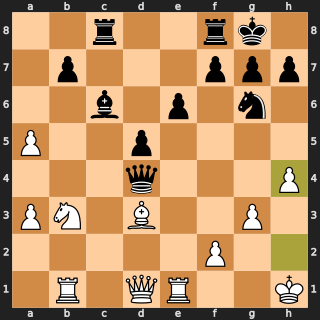

In [9]:
# --- TEMPERATURE SWEEP ---

# Header.
print(f"{'temperature':>12}{'legal':>8}{'strict':>9}")

# Four temperatures (0 = greedy).
for T in [1.0, 0.8, 0.5, 0]:

    # Same seed for each temperature.
    np.random.seed(0)

    # Evaluate.
    res_T = evaluate_model(temperature=T)

    # Row.
    print(f"{T:>12.1f}{np.mean([r[1] for r in res_T]):>8.1%}{np.mean([r[2] for r in res_T]):>9.1%}")

# --- EXAMPLES ---

# Title.
print("\nExamples (last moves of the context -> v5 move):")

# First 10 test positions.
for (moves, board), (k, legal, strict, san, mass) in zip(test_positions[:10], res_v5[:10]):

    # Verdict.
    verdict = "legal" if strict else ("legal, wrong notation" if legal else "illegal")

    # Last 4 moves of the context.
    tail = " ".join(moves[-4:]) if moves else "(start)"

    # Print.
    print(f"  ply {k:3d} | ...{tail:<28} -> {san:<8} {verdict:<22} p(legal) = {mass:.0%}")

# --- LONGEST LEGAL SELF-PLAY GAME ---

# Index of the longest game.
best = int(np.argmax(v5_plies))

# Its moves.
best_moves = v5_sequences[best]

# Print them with move numbers.
print(f"\nLongest legal self-play game ({len(best_moves)} plies):")

# Text with move numbers.
print(" ".join((f"{i // 2 + 1}. " if i % 2 == 0 else "") + m for i, m in enumerate(best_moves)))

# Replay it.
board = chess.Board()

# Each move.
for m in best_moves:

    # Play.
    board.push_san(m)

# Why it stopped.
print("Result:", board.outcome().termination.name if board.is_game_over() else "stopped by an illegal move or by the length limit")

# Draw the final position.
display(SVG(chess.svg.board(board, lastmove=board.peek() if best_moves else None, size=320)))

## Step 8 — Linear probes: does the model see the board?

### The question
The model only ever reads sequences like `; e4 e5 Nf3 Nc6 Bb5 …`. To predict legal moves well it would be useful to know **where every piece is**, but nobody ever gave it a board. Did it build one anyway, somewhere in its activations?

### The method
A **probe** is a small classifier trained on the hidden states of a frozen model. After reading $t$ moves, the residual stream at position $t$ and depth $\ell$ is a vector $h^{(\ell)}_t \in \mathbb{R}^{256}$. For each of the 64 squares $s$, a linear map predicts what is on it:

$$
\hat{y}_{t,s} = \arg\max_c \; \big(W_s\, \hat{h}^{(\ell)}_t + b_s\big)_c,
\qquad W_s \in \mathbb{R}^{13 \times 256}, \quad c \in \{\text{empty}, 6 \text{ pieces} \times 2 \text{ colours}\}
$$

where $\hat{h}$ is the hidden state standardised to mean 0 and variance 1 per dimension (computed on the probe's training data). All 64 squares together are one `nn.Linear(256, 64 * 13)`, trained with cross-entropy against the true board, which `python-chess` gives us by replaying the game.

**Why linear?** A powerful probe (a deep MLP) could compute the board by itself from almost any input that contains the moves. A *linear* probe can only read information that is already laid out explicitly in the activations. If a linear map succeeds, the board is *represented* by the model, not computed by the probe.

### Two ways of colouring the pieces
- **white / black**: classes "white pawn", …, "black king";
- **mine / theirs**: classes "pawn of the player to move", …, "king of the opponent".

The two contain exactly the same information (whose turn it is follows from the ply number). But they are not equally easy for a *linear* map. In a famous study of a GPT trained on the board game Othello (Li et al., 2023; Nanda et al., 2023), the board was linearly readable only in the "mine / theirs" form: the model thinks from the point of view of the player who is about to move. Is it the same for chess?

### Data and baselines
- Probe training: the positions of 2,000 validation games (every ply); probe test: positions of 1,000 *other* validation games. The model never trained on any of them.
- Depths $\ell = 0$ (embeddings only: the last move and the ply number) to $6$ (after the last block).
- **Baseline**: for each square, always predict its most frequent content in the probe training data.

We report the accuracy on all squares (inflated by the many empty squares), on **occupied squares** (the hard part), and the share of positions where **all 64 squares** are right.

Probe positions: 142,776 for training, 69,598 for testing (8s)
depth 0: occupied squares 65.0% (mine/theirs) | 60.3% (white/black) | perfect boards 2.6% | 18s
depth 1: occupied squares 70.7% (mine/theirs) | 66.6% (white/black) | perfect boards 2.7% | 28s
depth 2: occupied squares 76.7% (mine/theirs) | 71.8% (white/black) | perfect boards 3.4% | 42s
depth 3: occupied squares 80.9% (mine/theirs) | 75.3% (white/black) | perfect boards 2.8% | 55s
depth 4: occupied squares 81.8% (mine/theirs) | 76.5% (white/black) | perfect boards 2.7% | 69s
depth 5: occupied squares 82.8% (mine/theirs) | 77.2% (white/black) | perfect boards 2.7% | 84s
depth 6: occupied squares 83.7% (mine/theirs) | 77.9% (white/black) | perfect boards 3.0% | 100s

Baseline (most frequent content per square): occupied squares 1.3% (mine/theirs), 29.5% (white/black)
Best depth: 6 -> all squares 81.0%, occupied 83.7%, perfect boards 3.0%


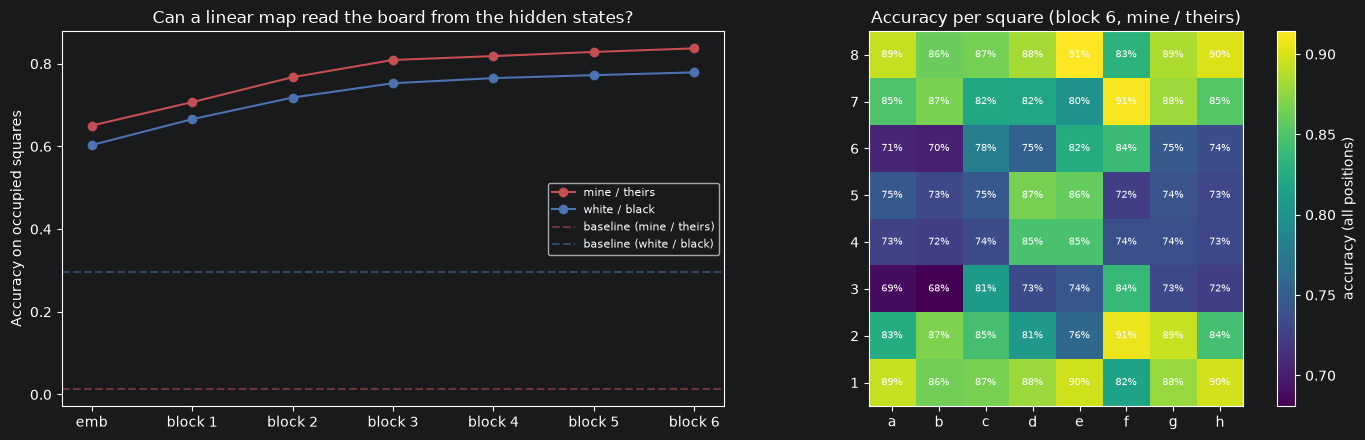

In [10]:
# --- LINEAR PROBES ---

# Games used to train the probes, and games used to test them (all from the validation split).
PROBE_TRAIN_GAMES = val_games[:2000]

# Different games for the probe test.
PROBE_TEST_GAMES = val_games[2000:3000]

# Number of classes per square: empty + 6 piece types x 2 colours.
N_CLASSES = 13


# Labels of the 64 squares of a position.
def board_labels(board, relative):
    """relative=True: 1-6 = pieces of the player to move, 7-12 = opponent; False: 1-6 white, 7-12 black. 0 = empty."""

    # All squares empty to start with.
    labels = np.zeros(64, dtype=np.int64)

    # Occupied squares only.
    for square, piece in board.piece_map().items():

        # "Own" piece: of the player to move (relative) or white (absolute).
        own = (piece.color == board.turn) if relative else (piece.color == chess.WHITE)

        # piece_type is 1 (pawn) ... 6 (king); opponent / black pieces are shifted by 6.
        labels[square] = piece.piece_type + (0 if own else 6)

    # The 64 labels.
    return labels


# Inputs and labels of a set of games.
def probe_dataset(game_list):
    """Return (list of input token arrays, relative labels (N, 64), absolute labels (N, 64)), one row per position."""

    # Model inputs, one array per game.
    inputs = []

    # Labels, one row per position.
    rel, ab = [], []

    # Each game.
    for g in game_list:

        # Its moves, at most BLOCK - 1 so that the input fits in the context.
        moves = g.split()[:BLOCK - 1]

        # Input tokens: ';' + the moves; position t of the input has read t moves.
        inputs.append(np.array(context_ids(moves), dtype=np.int64))

        # Replay the game.
        board = chess.Board()

        # Position 0: the starting position.
        rel.append(board_labels(board, True))

        # Absolute colours.
        ab.append(board_labels(board, False))

        # One position after every move.
        for m in moves:

            # Play the move.
            board.push_san(m)

            # Relative labels.
            rel.append(board_labels(board, True))

            # Absolute labels.
            ab.append(board_labels(board, False))

    # Inputs and label matrices.
    return inputs, np.stack(rel), np.stack(ab)


# Hidden states of a set of games after n_blocks blocks, one row per position, in the same order as the labels.
@torch.no_grad()
def extract_features(inputs, n_blocks, batch=32):
    """Return a float32 array (N positions, d)."""

    # Evaluation mode.
    model.eval()

    # Rows of the result.
    feats = []

    # Groups of games (in their original order, so that rows match the labels).
    for i in range(0, len(inputs), batch):

        # The games of this group.
        group = inputs[i:i + batch]

        # Longest input of the group, rounded up (few shapes, as in training).
        L = round_up(max(len(e) for e in group))

        # Padded matrix with a fixed number of rows (padding after the end does not change earlier positions: causal attention).
        mat = np.full((batch, L), PAD_ID, dtype=np.int64)

        # Copy every input.
        for r, e in enumerate(group):

            # Valid tokens first.
            mat[r, :len(e)] = e

        # Hidden states (B, L, d), on the CPU.
        h = model.hidden(torch.from_numpy(mat).to(device), n_blocks).cpu().numpy()

        # Keep only the real positions of every game.
        for r, e in enumerate(group):

            # One row per position.
            feats.append(h[r, :len(e)])

    # Back to training mode.
    model.train()

    # All positions.
    return np.concatenate(feats).astype(np.float32)


# Train one linear probe.
def train_probe(X, Y, epochs=4, batch=1024, lr=1e-3):
    """X: (N, d) features, Y: (N, 64) labels. Returns (probe, mean, std)."""

    # Standardisation statistics.
    mean, std = X.mean(axis=0), X.std(axis=0) + 1e-6

    # Standardised features as a tensor (CPU).
    Xt = torch.from_numpy((X - mean) / std)

    # Labels as a tensor.
    Yt = torch.from_numpy(Y)

    # One linear map d -> 64 x 13.
    probe = nn.Linear(X.shape[1], 64 * N_CLASSES).to(device)

    # Adam optimiser.
    opt = torch.optim.Adam(probe.parameters(), lr=lr)

    # Passes over the data.
    for _ in range(epochs):

        # Random order of the positions.
        perm = torch.randperm(len(Xt))

        # Mini-batches.
        for i in range(0, len(Xt), batch):

            # Indices of the batch.
            idx = perm[i:i + batch]

            # Logits (B, 64, 13).
            logits = probe(Xt[idx].to(device)).view(-1, 64, N_CLASSES)

            # Cross-entropy over all squares.
            loss = F.cross_entropy(logits.reshape(-1, N_CLASSES), Yt[idx].to(device).reshape(-1))

            # Reset gradients.
            opt.zero_grad()

            # Backpropagation.
            loss.backward()

            # Update.
            opt.step()

    # The trained probe and its standardisation.
    return probe, mean, std


# Predictions of a probe.
@torch.no_grad()
def probe_predict(probe, mean, std, X, batch=4096):
    """Return predicted classes (N, 64)."""

    # Predictions per batch.
    preds = []

    # Mini-batches.
    for i in range(0, len(X), batch):

        # Standardised features on the device.
        xb = torch.from_numpy((X[i:i + batch] - mean) / std).to(device)

        # Most likely class of every square.
        preds.append(probe(xb).view(-1, 64, N_CLASSES).argmax(-1).cpu().numpy())

    # All predictions.
    return np.concatenate(preds)


# Accuracy measures.
def probe_metrics(pred, true):
    """Return (accuracy on all squares, accuracy on occupied squares, share of perfect boards)."""

    # Correct squares.
    correct = pred == true

    # Occupied squares.
    occupied = true != 0

    # The three measures.
    return correct.mean(), correct[occupied].mean(), correct.all(axis=1).mean()


# --- DATASETS ---

# Start time.
start = time.perf_counter()

# Probe training positions.
tr_inputs, tr_rel, tr_abs = probe_dataset(PROBE_TRAIN_GAMES)

# Probe test positions.
te_inputs, te_rel, te_abs = probe_dataset(PROBE_TEST_GAMES)

# Report.
print(f"Probe positions: {len(tr_rel):,} for training, {len(te_rel):,} for testing ({time.perf_counter() - start:.0f}s)")

# --- BASELINE: MOST FREQUENT CONTENT OF EACH SQUARE ---

# Most frequent class of each square in the training positions (relative labels).
mode_rel = np.array([np.bincount(tr_rel[:, s], minlength=N_CLASSES).argmax() for s in range(64)])

# Same with absolute labels.
mode_abs = np.array([np.bincount(tr_abs[:, s], minlength=N_CLASSES).argmax() for s in range(64)])

# Baseline metrics (the same prediction for every position).
base_rel = probe_metrics(np.tile(mode_rel, (len(te_rel), 1)), te_rel)

# Absolute.
base_abs = probe_metrics(np.tile(mode_abs, (len(te_abs), 1)), te_abs)

# --- ONE PROBE PER DEPTH AND PER COLOURING ---

# Metrics per depth.
probe_results = {"relative": [], "absolute": []}

# Trained relative probes (kept for the visualisation).
rel_probes = []

# Depth 0 (embeddings) to N_LAYER (after the last block).
for depth in range(N_LAYER + 1):

    # Hidden states at this depth.
    X_tr = extract_features(tr_inputs, depth)

    # Test hidden states.
    X_te = extract_features(te_inputs, depth)

    # Relative ("mine / theirs") probe.
    probe, mu, sd = train_probe(X_tr, tr_rel)

    # Its test metrics.
    probe_results["relative"].append(probe_metrics(probe_predict(probe, mu, sd, X_te), te_rel))

    # Keep it.
    rel_probes.append((probe, mu, sd))

    # Absolute ("white / black") probe.
    probe_a, mu_a, sd_a = train_probe(X_tr, tr_abs)

    # Its test metrics.
    probe_results["absolute"].append(probe_metrics(probe_predict(probe_a, mu_a, sd_a, X_te), te_abs))

    # Report.
    print(f"depth {depth}: occupied squares {probe_results['relative'][-1][1]:.1%} (mine/theirs) | "
          f"{probe_results['absolute'][-1][1]:.1%} (white/black) | perfect boards {probe_results['relative'][-1][2]:.1%} | "
          f"{time.perf_counter() - start:.0f}s")

# Free the large feature arrays.
del X_tr, X_te

# Best depth for the relative probe (accuracy on occupied squares).
best_depth = int(np.argmax([m[1] for m in probe_results["relative"]]))

# Summary.
print(f"\nBaseline (most frequent content per square): occupied squares {base_rel[1]:.1%} (mine/theirs), {base_abs[1]:.1%} (white/black)")

# Best depth.
print(f"Best depth: {best_depth} -> all squares {probe_results['relative'][best_depth][0]:.1%}, "
      f"occupied {probe_results['relative'][best_depth][1]:.1%}, perfect boards {probe_results['relative'][best_depth][2]:.1%}")

# --- PLOTS ---

# Two panels.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# Depth labels.
depth_labels = ["emb"] + [f"block {l}" for l in range(1, N_LAYER + 1)]

# Relative probe, occupied squares.
ax1.plot(depth_labels, [m[1] for m in probe_results["relative"]], marker="o", color="#C44E52", label="mine / theirs")

# Absolute probe, occupied squares.
ax1.plot(depth_labels, [m[1] for m in probe_results["absolute"]], marker="o", color="#4C72B0", label="white / black")

# Baselines.
ax1.axhline(base_rel[1], linestyle="--", color="#C44E52", alpha=0.5, label="baseline (mine / theirs)")

# Absolute baseline.
ax1.axhline(base_abs[1], linestyle="--", color="#4C72B0", alpha=0.5, label="baseline (white / black)")

# y-axis label.
ax1.set_ylabel("Accuracy on occupied squares")

# Title.
ax1.set_title("Can a linear map read the board from the hidden states?")

# Legend.
ax1.legend(fontsize=8)

# Accuracy per square at the best depth (relative probe).
probe, mu, sd = rel_probes[best_depth]

# Test predictions at the best depth.
best_pred = probe_predict(probe, mu, sd, extract_features(te_inputs, best_depth))

# Accuracy of each square, as an 8 x 8 grid with rank 8 at the top (square index = 8 * rank + file).
square_acc = (best_pred == te_rel).mean(axis=0).reshape(8, 8)[::-1]

# Heatmap.
im = ax2.imshow(square_acc, cmap="viridis")

# Files a-h.
ax2.set_xticks(range(8), list("abcdefgh"))

# Ranks 8-1.
ax2.set_yticks(range(8), [str(r) for r in range(8, 0, -1)])

# Value in every cell.
for i in range(8):

    # Every file.
    for j in range(8):

        # Accuracy in percent.
        ax2.text(j, i, f"{square_acc[i, j]:.0%}", ha="center", va="center", fontsize=7, color="white")

# Colour bar.
fig.colorbar(im, ax=ax2, label="accuracy (all positions)")

# Title.
ax2.set_title(f"Accuracy per square ({depth_labels[best_depth]}, mine / theirs)")

# Layout.
plt.tight_layout()

# Render.
plt.show()

## Step 9 — The model's mind's eye

For a probe-test game (never seen in training), we read the board out of the hidden states with the best probe and draw it next to the real one. Squares where the probe is wrong are marked in red.

The probe works in "mine / theirs" form; to draw the board we turn it back into white and black using whose turn it is.

In [11]:
# --- REAL BOARD vs BOARD READ FROM THE MODEL ---

# Turn 64 relative labels back into a chess.Board.
def labels_to_board(labels, turn):
    """turn: the player to move (chess.WHITE or chess.BLACK). Returns a board with only the pieces."""

    # Empty board.
    b = chess.Board(None)

    # Every square.
    for square in range(64):

        # Its class.
        c = int(labels[square])

        # Not empty.
        if c:

            # Piece type 1-6.
            piece_type = (c - 1) % 6 + 1

            # Classes 1-6 belong to the player to move.
            colour = turn if c <= 6 else (not turn)

            # Put the piece.
            b.set_piece_at(square, chess.Piece(piece_type, colour))

    # The board.
    return b


# First probe-test game with at least 60 plies.
show_game = next(g for g in PROBE_TEST_GAMES if len(g.split()) >= 60)

# Its moves.
show_moves = show_game.split()

# Hidden states of that game at the best depth (one row per position).
show_feats = extract_features([np.array(context_ids(show_moves[:BLOCK - 1]), dtype=np.int64)], best_depth)

# Probe of the best depth.
probe, mu, sd = rel_probes[best_depth]

# Predicted labels of every position of the game.
show_pred = probe_predict(probe, mu, sd, show_feats)

# HTML with the boards.
html = ""

# Three moments of the game.
for t in [20, 40, 60]:

    # Real position after t moves.
    real = chess.Board()

    # Replay.
    for m in show_moves[:t]:

        # Play.
        real.push_san(m)

    # Board read from the model.
    seen = labels_to_board(show_pred[t], real.turn)

    # Squares where the probe is wrong.
    wrong = [s for s in range(64) if real.piece_at(s) != seen.piece_at(s)]

    # Real board, with the last move highlighted.
    real_svg = chess.svg.board(real, size=260, lastmove=real.peek())

    # Board read from the model, wrong squares in red.
    seen_svg = chess.svg.board(seen, size=260, fill={s: "#e0505099" for s in wrong})

    # One row: caption + two boards.
    html += (f"<div style='margin-bottom:16px'><b>After {t} plies (last move {show_moves[t - 1]}), "
             f"{'white' if real.turn else 'black'} to move: {64 - len(wrong)}/64 squares right</b>"
             f"<div style='display:flex;gap:24px'><div>Real board<br>{real_svg}</div>"
             f"<div>Read from the model ({depth_labels[best_depth]})<br>{seen_svg}</div></div></div>")

# Show.
display(HTML(html))

## Step 10 — Save the model and the results

- The results of v5 are added to the shared file, with the strict legality and the probe accuracies.
- The **trained model** is saved to `data`, together with its vocabulary and configuration: the web app of v6 will load it to let you play against ChessGPT.

In [12]:
# --- SAVE THE RESULTS OF v5 ---

# Results of the move-level GPT.
results_all["v5_move_gpt"] = {
    # Equivalent bits per character on the validation games.
    "val_bpc_equivalent": float(bpc_eq),
    # Bits per move on the validation games.
    "val_bits_per_move": float(bits_per_move),
    # Legal move rate at temperature 1 (lenient, as v1-v4).
    "legal_rate": float(legal_v5),
    # Strictly legal move rate.
    "strict_legal_rate": float(strict_v5),
    # Mean probability on legal moves.
    "legal_probability_mass": float(mass_v5),
    # Well-formed rate.
    "well_formed_rate": float(wf_v5),
    # Mean legal plies in self-play.
    "selfplay_mean_plies": float(np.mean(v5_plies)),
    # Legal rate in each phase bin.
    "phase_legal_rates": [float(r) for r in phase_legal],
    # Strict legal rate in each phase bin.
    "phase_strict_rates": [float(r) for r in phase_strict],
    # Probe accuracy on occupied squares per depth (mine / theirs).
    "probe_occupied_accuracy_relative": [float(m[1]) for m in probe_results["relative"]],
    # Same with white / black.
    "probe_occupied_accuracy_absolute": [float(m[1]) for m in probe_results["absolute"]],
    # Number of parameters.
    "params": int(n_params),
}

# Write the file.
RESULTS_PATH.write_text(json.dumps(results_all, indent=2))

# Show the v5 entry.
print(json.dumps(results_all["v5_move_gpt"], indent=2))

# --- SAVE THE MODEL FOR v6 ---

# Checkpoint path.
MODEL_PATH = DATA_DIR / "chessgpt_v5.pt"

# Weights, vocabulary and configuration in one file.
torch.save({
    # All weights (moved to the CPU so the file loads on any machine).
    "model_state": {k: v.cpu() for k, v in model.state_dict().items()},
    # The vocabulary, in index order.
    "vocab": vocab,
    # Everything needed to rebuild the model.
    "config": {"block": BLOCK, "n_embd": N_EMBD, "n_head": N_HEAD, "n_layer": N_LAYER},
}, MODEL_PATH)

# Report.
print(f"\nModel saved to {MODEL_PATH} ({MODEL_PATH.stat().st_size / 1024**2:.1f} MB)")

{
  "val_bpc_equivalent": 1.018507529307887,
  "val_bits_per_move": 4.154420033559685,
  "legal_rate": 0.751,
  "strict_legal_rate": 0.709,
  "legal_probability_mass": 0.7015239136871607,
  "well_formed_rate": 0.99,
  "selfplay_mean_plies": 18.725,
  "phase_legal_rates": [
    0.9822485207100592,
    0.93717277486911,
    0.7395833333333334,
    0.55,
    0.5416666666666666
  ],
  "phase_strict_rates": [
    0.9822485207100592,
    0.9319371727748691,
    0.6944444444444444,
    0.48214285714285715,
    0.4166666666666667
  ],
  "probe_occupied_accuracy_relative": [
    0.6503985113317555,
    0.7070827036536094,
    0.7674643918440618,
    0.8090517674216211,
    0.818445824402109,
    0.8284386711577966,
    0.837119263302617
  ],
  "probe_occupied_accuracy_absolute": [
    0.603188958465313,
    0.6658188977061269,
    0.7181454377302025,
    0.7527791655870681,
    0.765181428342964,
    0.7723526487459508,
    0.7789858261625262
  ],
  "params": 6274905
}

Model saved to ../data/l

## Results and conclusions

### Summary
| Model | Parameters | Unit | Val bits/char | Legal | Strict | Self-play plies |
|---|---|---|---|---|---|---|
| Frequency baseline | — | move | — | 11.2% | 9.1% | — |
| v1 Bigram | 841 | character | 2.430 | 10.2% | — | 0.31 |
| v2 MLP + embeddings | 475,349 | character | 1.558 | 36.9% | — | 6.58 |
| v3 LSTM | 1,883,869 | character | 1.258 | 55.4% | — | 10.43 |
| v4 GPT | 2,779,037 | character | 1.282 | 56.9% | — | 10.46 |
| **v5 move GPT** | **6,274,905** | **move** | **1.019** (equivalent) | **75.6%** | **71.0%** | **18.72** |

The biggest jump of the project:
- **+18.7 points** of legal move rate over the best character model;
- **−0.24 bits per character**: about 19% less information needed to describe a validation game;
- self-play games **1.8 times longer**.

Caveat: v5 changed three things at once (move tokens, 3 times more data, a bigger model), so this run cannot tell how much of the gain comes from each. A fair **ablation** would train the move model on January only, or the character GPT on three months.

### Training
- 3,304 steps in about 27 minutes on an 8 GB M1 (0.48 s/step): one pass over 27 million moves.
- Validation: **4.155 bits per move**, perplexity 17.8. On average the model hesitates between about 18 moves, while a typical position has 30–40 legal moves: it concentrates on the plausible ones.
- The validation loss was still decreasing at the end (4.26 → 4.22 in the last 300 steps): more data or more steps would still help.
- A gap of about 0.3 bits per move opened between training and validation. With a single pass this is not classic overfitting: batches are drawn with replacement, so some games are seen twice, and the most common opening sequences repeat across many games. Validation kept improving, so it did no harm here.
- The gradient norm stays at about 0.85–0.9, just below the clipping threshold, which was active only in the first few hundred steps.
- Memory: an 8 GB Mac needed a **token budget** per batch and only **8 tensor shapes**, otherwise the `mps` backend runs out of memory.

### Legality
| Plies already played | v3 LSTM | v4 GPT | v5 legal | v5 strict | v5 p(legal) |
|---|---|---|---|---|---|
| 0–9 | 91.1% | 94.7% | **98.8%** | 98.2% | 98.5% |
| 10–19 | 75.9% | 73.8% | **95.3%** | 94.2% | 91.6% |
| 20–39 | 42.7% | 46.5% | **75.0%** | 70.1% | 68.6% |
| 40–79 | 34.6% | 40.4% | **55.7%** | 47.1% | 47.7% |
| 80+ | 48.6% | 29.2% | **48.6%** | 41.7% | 40.7% |

- The gain is largest in the **middle game**: +28.5 points at plies 20–39 compared with v4.
- In long games (80+) v5 recovers the level of the LSTM: with 256 plies of context it always sees the whole game, while the v4 window lost the beginning.
- **Strict vs lenient**: 4.6 points of the legal moves have the right piece and square but wrong notation (a missing or extra `x`, `+` or `#`). The numbers of v1–v4 are lenient; their strict values would be lower too.
- **p(legal) = 70.2%**: on average the model puts 70% of its probability on moves that are actually possible, 98.5% in the opening and still 47.7% at plies 40–79.
- **Well-formed 98.9%**: every move token is a real move, so the 1.1% are special tokens sampled instead of a move, mostly `;`: the model "thinks" the game is over.

### Temperature
| Temperature | Legal | Strict |
|---|---|---|
| 1.0 | 75.6% | 71.0% |
| 0.8 | 79.8% | 75.8% |
| 0.5 | 84.4% | 81.4% |
| 0 (most likely move) | **87.8%** | **85.8%** |

Always choosing the most likely move gives **87.8%** legal moves. Many errors at $T = 1$ come from the tail of the distribution: in the example at ply 8 the model put 97% of its probability on legal moves, but the sampled move `Bd2` came from the remaining 3%.

### Examples and self-play
- On the same 10 test positions: 8 legal moves out of 10 (v4: 8, v3: 5), several with high confidence (`d5` after `g3` with 100% on legal moves).
- Self-play: mean **18.7 legal plies** (17.7 strictly legal), maximum **45**. One game out of 200 even reached a regular end (mate, stalemate or draw).
- Longest game: `1.e4 c6 2.Nf3 d5 3.exd5 cxd5 4.Nc3 Nc6 5.Bb5 Bg4 6.O-O a6 7.Bxc6+ bxc6 8.h3 Bxf3 9.Qxf3 e6 10.d4 Nf6 11.Bg5 Be7 …`, a coherent Caro-Kann with natural recaptures (`Bxc6+ bxc6`, `Bxf3 Qxf3`), castling and piece development for over 20 moves.

### Linear probes: the model's picture of the board
| Depth | Occupied squares (mine / theirs) | Occupied squares (white / black) |
|---|---|---|
| embeddings | 65.0% | 60.3% |
| block 1 | 70.7% | 66.6% |
| block 2 | 76.7% | 71.8% |
| block 3 | 80.9% | 75.3% |
| block 4 | 81.8% | 76.5% |
| block 5 | 82.8% | 77.2% |
| block 6 | **83.7%** | **77.9%** |

- **The board is built layer by layer.** From the embeddings alone (the last move and the ply number) a linear map already gets 65%, because many pieces stay on their starting squares for a long time. Every block adds information, up to **83.7%** after block 6. The model was never shown a board: it reconstructed it from the moves.
- **"Mine / theirs" beats "white / black" at every depth**, by 4.5–6 points. As in Othello-GPT, the model represents the board from the point of view of the player who is about to move. The two labelings contain the same information; only the linear readability differs.
- The per-square baseline is weak (29.5% white/black; 1.3% mine/theirs, because colours swap at every ply and the most frequent content of most squares becomes "empty"). The **embedding probe (65%) is the more meaningful baseline**: the layers add about 19 points on top of it.
- **Per square**: the back ranks are read best (82–91%), ranks 3–6 worst (68–87%). Pieces start on the back ranks and many never leave, while the middle of the board is where pieces arrive and leave.
- **Perfect boards: only 3%** (81% of all squares right). The picture is approximately right but almost never exact in every square, as in the mind's-eye boards: 57/64 squares right after 20 plies, 43/64 after 40, 46/64 after 60.
- Caveats: the probe was trained for 4 epochs only, and its accuracy on all squares (81.0%) is slightly below that on occupied squares, so it also puts pieces on some empty squares. A longer-trained probe could do better. A linear probe gives a **lower bound** on what the model represents.

### Limits and next step
- At temperature 1, 29% of the moves are still strictly illegal, and the internal board is rarely exact. More data (Lichess publishes years of games), a bigger model and a GPU (Colab) would push further.
- The trained model is saved in `data` (29.6 MB), with its vocabulary and configuration.
- **v6, the web app:** play against ChessGPT in the browser, with an option to **mask illegal moves** (sample only among legal moves, using the probabilities of the model), and live views of its probabilities and of the board it "sees" through the probe.

In [13]:
# --- SAVE THE PROBE FOR THE APP ---

# "Mine / theirs" probe of the best depth, with its standardisation.
probe, mu, sd = rel_probes[best_depth]

# Probe path, next to the model.
PROBE_PATH = DATA_DIR / "chessgpt_v5_probe.pt"

# Weights on the CPU, standardisation as tensors, depth as an int (only tensors and numbers: loadable with weights_only).
torch.save({"state": {k: v.cpu() for k, v in probe.state_dict().items()},
            "mean": torch.from_numpy(mu), "std": torch.from_numpy(sd), "depth": best_depth}, PROBE_PATH)

# Report.
print(f"Probe saved to {PROBE_PATH} (depth {best_depth})")

Probe saved to ../data/lichess/chessgpt_v5_probe.pt (depth 6)
